## EDA PERSONAL DEPENDIENTE

In [29]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [30]:
#Load data
df = pd.read_csv(r"D:\oliver.navarro\Downloads\conjunto_de_datos_ems_mensual_csv\conjunto_de_datos\tr_ems_nacional_indice_2008_2026.csv")
df.head()

,CODIGO_ACTIVIDAD,ANIO,MES,M000,H000A,H000,I000A,K000,J000,ESTATUS
0,,2008,1,99.434898,96.137325,NaN,NaN,82.931279,105.538666,Cifras definitivas
1,,2008,2,96.251368,95.158782,NaN,NaN,82.396875,102.919716,Cifras definitivas
2,,2008,3,105.286368,96.632545,NaN,NaN,87.514543,108.458924,Cifras definitivas
3,,2008,4,97.356048,96.991156,NaN,NaN,83.433971,104.395181,Cifras definitivas
4,,2008,5,101.784105,96.424027,NaN,NaN,81.627400,126.555281,Cifras definitivas


In [31]:
df = df[(df["CODIGO_ACTIVIDAD"] == "62") & (df["ESTATUS"] == "Cifras definitivas")] #Filter data and  Definitive Data
df = df.set_index(pd.to_datetime(df['ANIO'].astype(str) + '-' + df['MES'].astype(str))) # Set date index
df.isna().sum()

CODIGO_ACTIVIDAD     0
ANIO                 0
MES                  0
M000                 0
H000A                0
H000                60
I000A               60
K000                 0
J000                 0
ESTATUS              0
dtype: int64

In [32]:
df= df.drop(["ANIO","MES","CODIGO_ACTIVIDAD","ESTATUS"],axis=1) #Drop columns used to set the date time and columns that dont give information
df.rename(columns={
        'M000': 'Ingresos Total',
        'H000A': 'PO Total',
        'H000': 'Personal Dep',
        'I000A': 'Personal No Dep',
        'K000': 'Gastos Totales',
        'J000': 'Remuneraciones Totales'},inplace=True)
df.head()

,Ingresos Total,PO Total,Personal Dep,Personal No Dep,Gastos Totales,Remuneraciones Totales
2008-01-01,122.935519,99.340247,NaN,NaN,99.576566,104.658670
2008-02-01,95.710736,94.090691,NaN,NaN,83.959878,100.087098
2008-03-01,106.599528,95.422496,NaN,NaN,89.456126,100.647387
2008-04-01,93.909550,94.115819,NaN,NaN,86.016221,99.232265
2008-05-01,103.721049,94.689956,NaN,NaN,93.805278,112.650903


In [33]:
df2= df.dropna()
df2.head()

,Ingresos Total,PO Total,Personal Dep,Personal No Dep,Gastos Totales,Remuneraciones Totales
2013-01-01,87.527401,92.604327,93.661239,131.324672,80.189917,86.009114
2013-02-01,80.949419,90.444054,92.625980,73.980145,80.438785,82.295950
2013-03-01,82.622170,90.656015,92.993873,74.713243,79.923183,84.385615
2013-04-01,83.567972,90.517254,92.877319,74.892248,82.347400,86.652131
2013-05-01,82.934907,90.830960,93.231147,76.370131,83.845869,89.986082


In [34]:
df.index.freq = "MS"

In [35]:
df2.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 144 entries, 2013-01-01 to 2024-12-01
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Ingresos Total          144 non-null    float64
 1   PO Total                144 non-null    float64
 2   Personal Dep            144 non-null    float64
 3   Personal No Dep         144 non-null    float64
 4   Gastos Totales          144 non-null    float64
 5   Remuneraciones Totales  144 non-null    float64
dtypes: float64(6)
memory usage: 7.9 KB


Text(0.5, 0, 'Fecha')

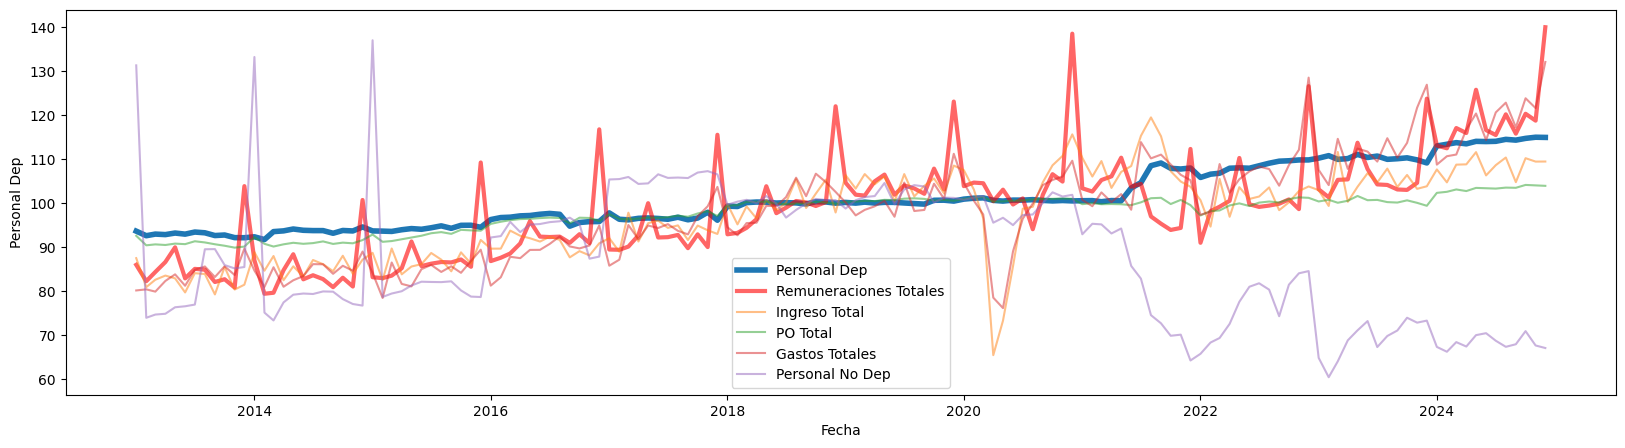

In [36]:
plt.figure(figsize=(20, 5))
sns.lineplot(data=df2,x=df2.index,y="Personal Dep",label="Personal Dep",linewidth=4)
sns.lineplot(data=df2,x=df2.index,y="Remuneraciones Totales",label="Remuneraciones Totales",linewidth=3,color="red",alpha=0.6)
sns.lineplot(data=df2,x=df2.index,y="Ingresos Total",label="Ingreso Total",alpha=0.5)
sns.lineplot(data=df2,x=df2.index,y="PO Total",label="PO Total",alpha=0.5)
sns.lineplot(data=df2,x=df2.index,y="Gastos Totales",label="Gastos Totales",alpha=0.5)
sns.lineplot(data=df2,x=df2.index,y="Personal No Dep",label="Personal No Dep",alpha=0.5)
plt.xlabel("Fecha")

## SARIMA PERSONAL DEPENDIENTE

### Prueba de estacionalidad

In [37]:
from statsmodels.tsa.stattools import adfuller

    # Ho: La serie NO es estacionaria
    # H1: La serie es estacionaria

results = adfuller(df2["Personal Dep"])
print("ADF Statistic:", results[0])
print("p-value:", results[1])
 # Como nos arrojo un valor p > 0.05 Aceptamos H0 que no es estacionaria por lo que procedemos a hacerla estacionaria

ADF Statistic: 0.46989236420414154
p-value: 0.9839286932343911


In [55]:
### Se necesita Diferenciar para volver la serie estacionaria
df2_pd= df2['Personal Dep']
df2_pd_stationary=df2_pd.diff().dropna() 

results= adfuller(df2_pd_stationary)
print("ADF Statistic:", results[0])
print("p-value:", results[1])

#Se uso una diferenciacion para volver la serie estacionaria por lo que d=1

ADF Statistic: -13.71077707853262
p-value: 1.2389071883586476e-25


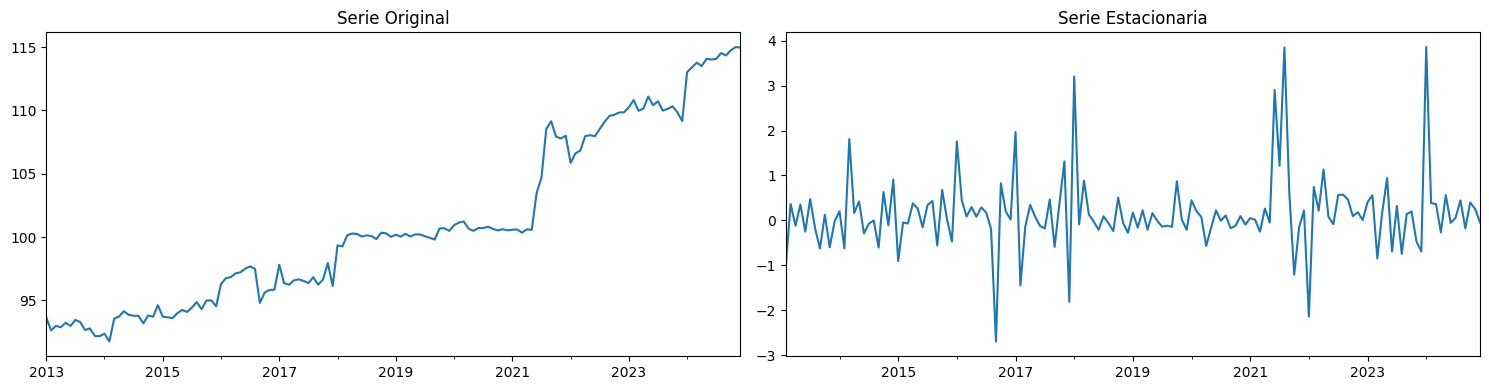

In [56]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4))

df2_pd.plot(ax=ax1)
ax1.set_title("Serie Original")

df2_pd_stationary.plot(ax=ax2)
ax2.set_title("Serie Estacionaria")

plt.tight_layout()
plt.show()

### Estimacion Ordenes AR(p) y MA(q)


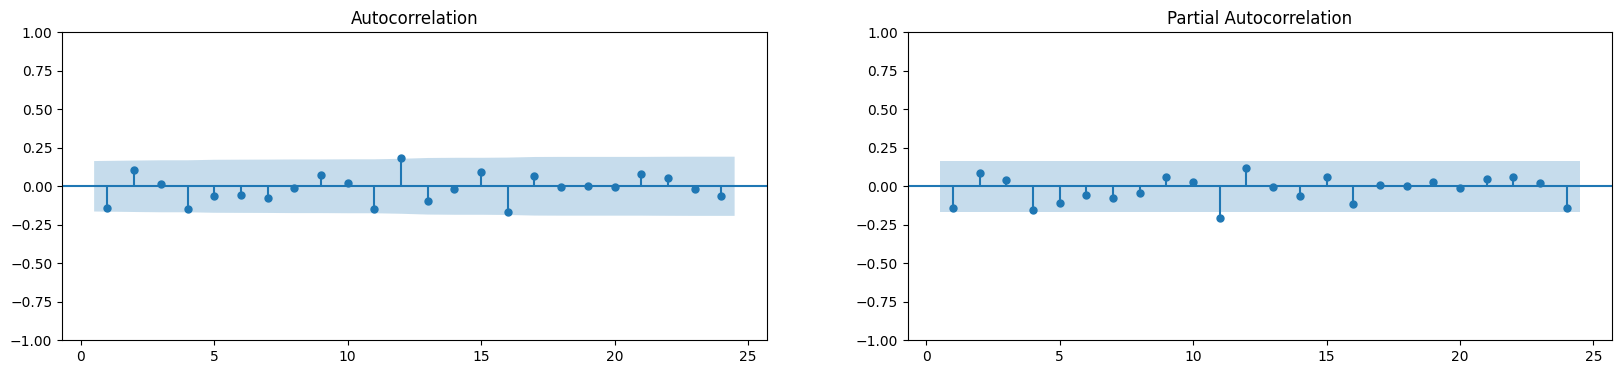

In [57]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 4))

plot_acf(df2_pd_stationary, lags=24, zero=False, ax=ax1)
plot_pacf(df2_pd_stationary, lags=24, zero=False, ax=ax2)
plt.show()

# La grafica ACF muestra una poca autocorrelacion en los primeros lags, pero un pico positivo en el lag 12, 
                    #  como los datos son mensuales, existe evidencia de una posible estacionalidad anual.
# La grafica PACF no muestra una relacion autorregresiva parcial, existiendo el mismo pico en el lag 12, 
                    # por lo que posiblemente haya una estacionalidad anual.

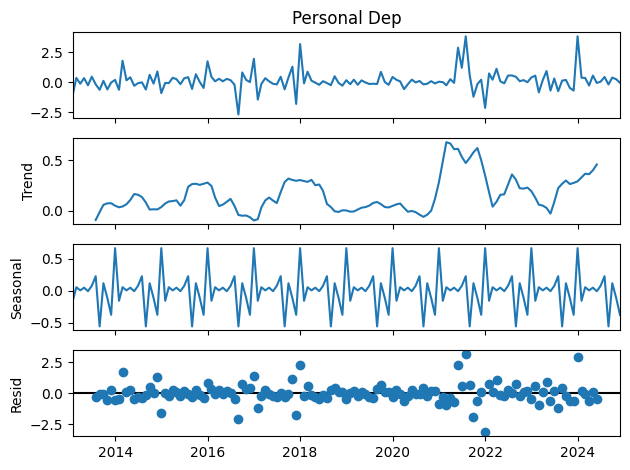

In [58]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomp = seasonal_decompose(df2_pd_stationary,period=12)

decomp.plot()
plt.show()

### Entrenamiento, ajuste y predicciones del modelo

In [64]:
import pmdarima as pm
results_model= pm.auto_arima(df2_pd,start_p=1,start_q=1,
                        seasonal=True,m=12,
                        information_criterion="aic",
                        trace=True,error_action="ignore",stepwise=True)

order = results_model.order
seasonal_order = results_model.seasonal_order
# El modelo óptimo seleccionado por AIC es ARIMA(0,1,0)(0,0,1)[12].
#    Al incluir el intercepto sobre la serie diferenciada (d=1), el modelo logra proyectar la tendencia
#    de crecimiento histórica del Sector 62 sin quedarse estancado.
#    Estacionalidad: El componente MA estacional (Q=1, s=12) captura la memoria de los últimos 12 meses
#    para ajustar las variaciones anuales sin requerir diferenciación estacional (D=0).

Performing stepwise search to minimize aic
 ARIMA(1,1,1)(1,0,1)[12] intercept   : AIC=354.978, Time=0.19 sec
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=355.950, Time=0.02 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=352.817, Time=0.06 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=352.177, Time=0.06 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=358.499, Time=0.01 sec
 ARIMA(0,1,1)(0,0,0)[12] intercept   : AIC=355.592, Time=0.02 sec
 ARIMA(0,1,1)(1,0,1)[12] intercept   : AIC=354.009, Time=0.10 sec
 ARIMA(0,1,1)(0,0,2)[12] intercept   : AIC=353.888, Time=0.13 sec
 ARIMA(0,1,1)(1,0,0)[12] intercept   : AIC=353.092, Time=0.05 sec
 ARIMA(0,1,1)(1,0,2)[12] intercept   : AIC=355.613, Time=0.40 sec
 ARIMA(0,1,0)(0,0,1)[12] intercept   : AIC=351.227, Time=0.04 sec
 ARIMA(0,1,0)(1,0,1)[12] intercept   : AIC=353.089, Time=0.08 sec
 ARIMA(0,1,0)(0,0,2)[12] intercept   : AIC=353.000, Time=0.09 sec
 ARIMA(0,1,0)(1,0,0)[12] intercept   : AIC=352.315, Time=0.04 sec
 ARIMA(0,1,0)(1,0,2)[12] intercep

In [65]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

model = SARIMAX(df2_pd, order= order, seasonal_order= seasonal_order)
results = model.fit()
print(results.summary())

# Como la Prueba(Q) > 0.05, no rechazamos la Ho, por lo que NO PRESENTAN AUTO CORRELACION
# Como la Prueba(JB) < 0.05, rechazamos la Ho, por lo que los residuos NO siguen una distribucion normal devido a los outliers

                                      SARIMAX Results                                       
Dep. Variable:                         Personal Dep   No. Observations:                  144
Model:             SARIMAX(0, 1, 0)x(0, 0, [1], 12)   Log Likelihood                -174.268
Date:                              Thu, 19 Nov 2026   AIC                            352.537
Time:                                      09:07:59   BIC                            358.463
Sample:                                  01-01-2013   HQIC                           354.945
                                       - 12-01-2024                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.S.L12       0.2561      0.091      2.813      0.005       0.078       0.435
sigma2         0.66

c:\dev\python\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\dev\python\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


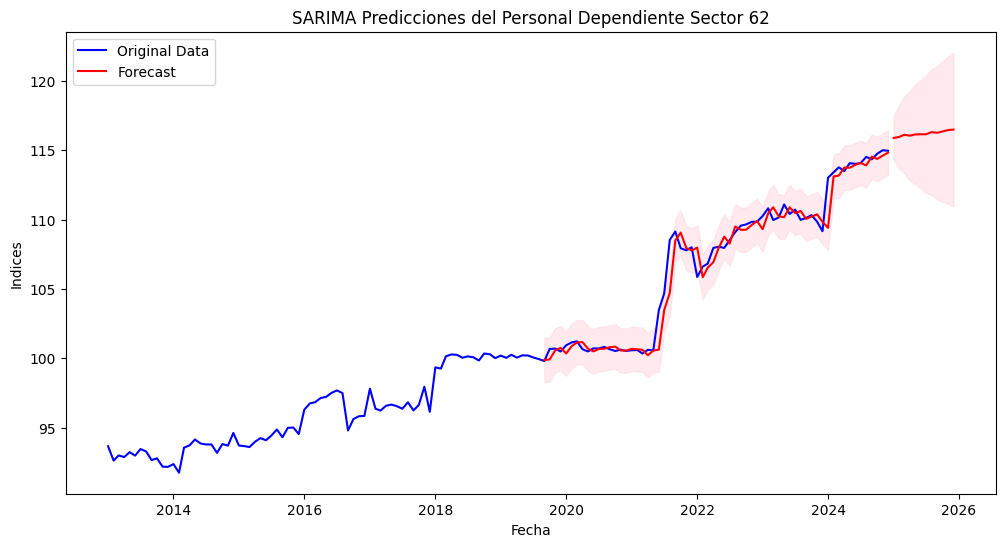

In [66]:
forecast = results.get_forecast(steps=12)
mean_forecast = forecast.predicted_mean
confidence_intervals = forecast.conf_int()

pred_dm = results.get_prediction(start=-64)
mean_pred = pred_dm.predicted_mean
confidence_intervals_dm = pred_dm.conf_int()

plt.figure(figsize=(12, 6))
plt.plot(df2_pd.index,df2_pd.values,color="blue",label="Original Data")

# Forecast
plt.plot(mean_forecast.index,mean_forecast.values,color="red",label="Forecast")
plt.fill_between(confidence_intervals.index,confidence_intervals.iloc[:, 0],confidence_intervals.iloc[:, 1],color="pink",alpha=0.3)

# Prediction
plt.plot(mean_pred.index,mean_pred.values,color="red")
plt.fill_between(confidence_intervals_dm.index,confidence_intervals_dm.iloc[:,0],confidence_intervals_dm.iloc[:,1],color="pink",alpha=0.3)

plt.legend()
plt.title("SARIMA Predicciones del Personal Dependiente Sector 62")
plt.xlabel("Fecha")
plt.ylabel("Indices")
plt.show()

In [68]:
#Residuos
residuals= results.resid.iloc[1:]

mse = np.mean(residuals ** 2) #Error cuadratico medio
rmse = np.sqrt(mse) #Raiz del error cuadratico medio
mae= np.mean(np.abs(residuals)) #Error absuluto medio 

print(f"MAE: {round(mae, 5)}")
print(f"MSE: {round(mse, 5)}")
print(f"RMSE: {round(rmse, 5)}")

# 3. Precisión: Con un MAE de 0.49587 y un RMSE de 0.81693, el modelo presenta un error promedio de
#    aproximadamente 0.5 puntos mes a mes, siendo altamente preciso en el corto plazo y consistente
#    para proyecciones anuales de hasta 12 meses.

MAE: 0.49587
MSE: 0.66738
RMSE: 0.81693


In [46]:
# Ver los 5 meses donde el modelo tuvo mayor error
print(results.resid.iloc[1:].abs().sort_values(ascending=False).head(5))


2014-01-01    46.625986
2024-01-01     3.864049
2021-08-01     3.816951
2021-06-01     2.829558
2019-01-01     2.462859
dtype: float64


## SARIMAX

In [47]:
COVID=np.where(df2_pd.index.year.isin([2020,2021]), 1, 0)
import pmdarima as pm
results_model2= pm.auto_arima(df2_pd,d=1,start_p=1,start_q=1,
                        seasonal=True,m=12,exog=COVID,trend="c",
                        information_criterion="aic",
                        trace=True,error_action="ignore",stepwise=True)

order2 = results_model2.order
seasonal_order2 = results_model2.seasonal_order

Performing stepwise search to minimize aic
 ARIMA(1,1,1)(1,0,1)[12] intercept   : AIC=354.978, Time=0.22 sec
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=355.950, Time=0.02 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=352.817, Time=0.06 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=352.177, Time=0.06 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=355.950, Time=0.02 sec
 ARIMA(0,1,1)(0,0,0)[12] intercept   : AIC=355.592, Time=0.02 sec
 ARIMA(0,1,1)(1,0,1)[12] intercept   : AIC=354.009, Time=0.12 sec
 ARIMA(0,1,1)(0,0,2)[12] intercept   : AIC=353.888, Time=0.12 sec
 ARIMA(0,1,1)(1,0,0)[12] intercept   : AIC=353.092, Time=0.05 sec
 ARIMA(0,1,1)(1,0,2)[12] intercept   : AIC=355.613, Time=0.40 sec
 ARIMA(0,1,0)(0,0,1)[12] intercept   : AIC=351.227, Time=0.04 sec
 ARIMA(0,1,0)(1,0,1)[12] intercept   : AIC=353.089, Time=0.09 sec
 ARIMA(0,1,0)(0,0,2)[12] intercept   : AIC=353.000, Time=0.10 sec
 ARIMA(0,1,0)(1,0,0)[12] intercept   : AIC=352.315, Time=0.05 sec
 ARIMA(0,1,0)(1,0,2)[12] intercep

In [48]:
model2 = SARIMAX(df2_pd, order= order2, seasonal_order= seasonal_order2,exog=COVID)
results2 = model2.fit()
print(results2.summary())

#Podemos observar que la variable Exogena segun su valor p (0.025)<0.05,
# y un valor Z de 2.248 > 1.96, por lo que la variable es significativa para el comportamiento de la serie.

                                      SARIMAX Results                                       
Dep. Variable:                         Personal Dep   No. Observations:                  144
Model:             SARIMAX(0, 1, 0)x(0, 0, [1], 12)   Log Likelihood                -171.690
Date:                              Thu, 19 Nov 2026   AIC                            349.380
Time:                                      09:01:36   BIC                            358.269
Sample:                                  01-01-2013   HQIC                           352.992
                                       - 12-01-2024                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1             1.2989      0.578      2.248      0.025       0.166       2.432
ma.S.L12       0.25

c:\dev\python\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\dev\python\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


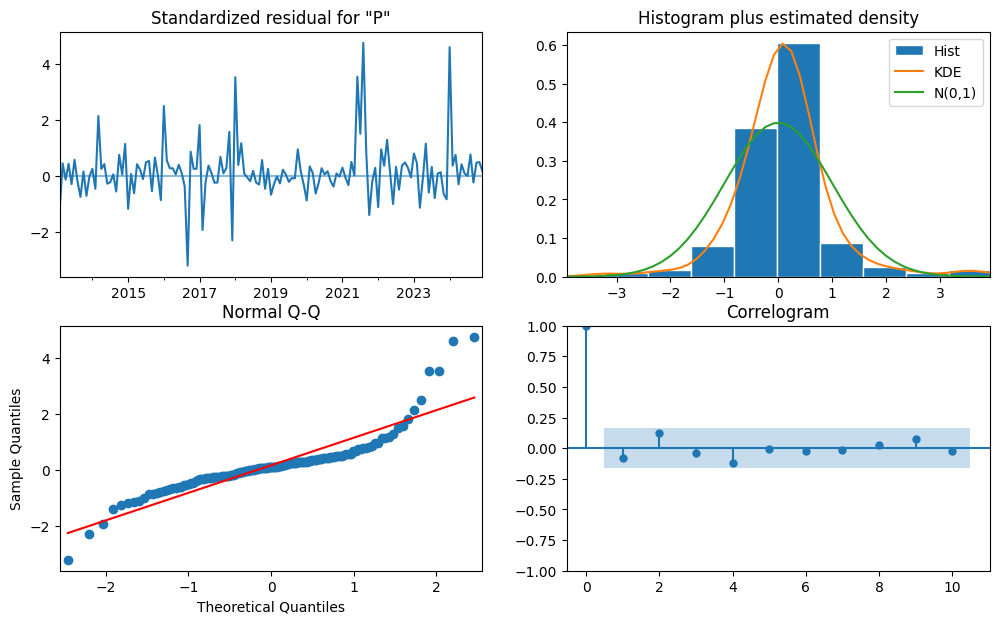

In [49]:
results2.plot_diagnostics(figsize=(12,7))
plt.show()

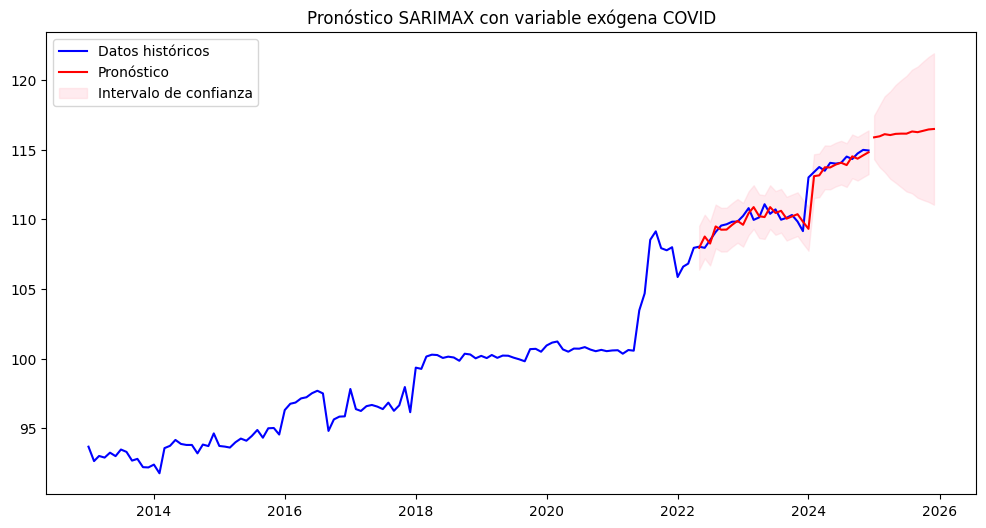

In [50]:
future_dates = pd.date_range(start=df2_pd.index[-1] + pd.DateOffset(months=1),periods=12,freq='MS')

# Variable exógena futura
COVID_future = np.where(future_dates.year.isin([2020, 2021]),1, 0).reshape(-1, 1)

# Pronóstico
forecast2 = results2.get_forecast(steps=12,exog=COVID_future)
mean_forecast = forecast2.predicted_mean
confidence_intervals = forecast2.conf_int()

pred_dm2 = results2.get_prediction(start=-32)
mean_pred2 = pred_dm2.predicted_mean
confidence_intervals_dm2 = pred_dm2.conf_int()

# Gráfica
plt.figure(figsize=(12, 6))

plt.plot(df2_pd, label='Datos históricos', color="blue")
plt.plot(future_dates, mean_forecast, label='Pronóstico', color='red')

plt.fill_between(future_dates,confidence_intervals.iloc[:, 0],confidence_intervals.iloc[:, 1],color='pink',
    alpha=0.3,label='Intervalo de confianza')

plt.plot(mean_pred2.index,mean_pred2.values,color="red")
plt.fill_between(confidence_intervals_dm2.index,confidence_intervals_dm2.iloc[:,0],confidence_intervals_dm2.iloc[:,1],color="pink",alpha=0.3)

plt.title('Pronóstico SARIMAX con variable exógena COVID')
plt.legend()
plt.show()

In [51]:
#Residuos
residuals2= results2.resid.iloc[1:]

mse = np.mean(residuals2 ** 2) #Error cuadratico medio
rmse = np.sqrt(mse) #Raiz del error cuadratico medio
mae= np.mean(np.abs(residuals2)) #Error absuluto medio 

print(f"MAE: {round(mae, 5)}")
print(f"MSE: {round(mse, 5)}")
print(f"RMSE: {round(rmse, 5)}")

# 3. Precisión: Con un MAE de 0.49587 y un RMSE de 0.81693, el modelo presenta un error promedio de
#    aproximadamente 0.5 puntos mes a mes, siendo altamente preciso en el corto plazo y consistente
#    para proyecciones anuales de hasta 12 meses.

MAE: 0.48743
MSE: 0.6438
RMSE: 0.80237


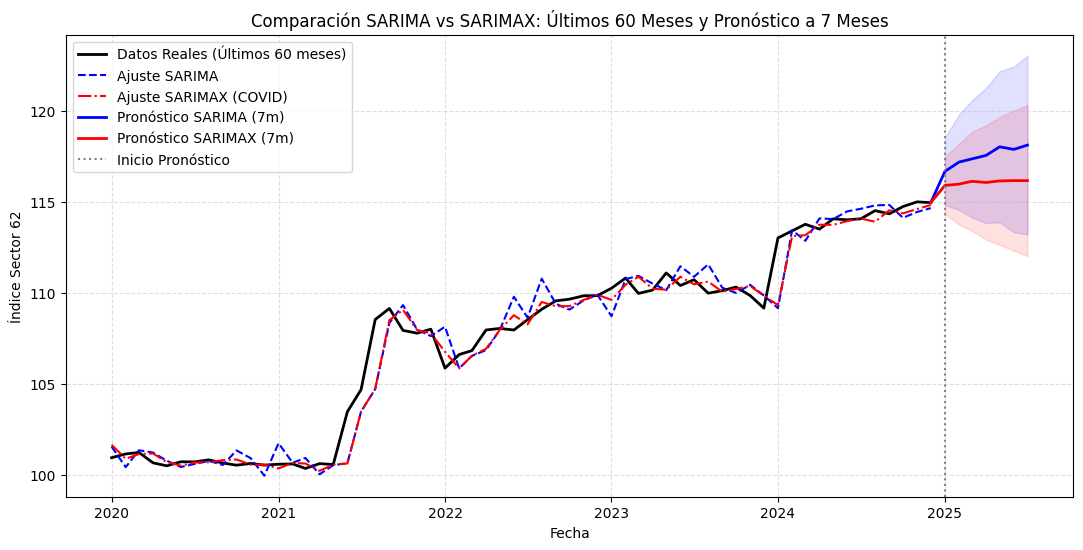

In [52]:

pred_sarima_36 = results.get_prediction(start=-60).predicted_mean
pred_sarimax_36 = results2.get_prediction(start=-60).predicted_mean

pasos = 7
COVID_future = np.zeros((pasos, 1))

fc_sarima = results.get_forecast(steps=pasos)
mean_fc_sarima = fc_sarima.predicted_mean
ci_sarima = fc_sarima.conf_int()

fc_sarimax = results2.get_forecast(steps=pasos, exog=COVID_future)
mean_fc_sarimax = fc_sarimax.predicted_mean
ci_sarimax = fc_sarimax.conf_int()

ultimo_dato = df2_pd.iloc[-1:]
linea_sarima = pd.concat([ultimo_dato, mean_fc_sarima])
linea_sarimax = pd.concat([ultimo_dato, mean_fc_sarimax])

plt.figure(figsize=(13, 6))

# Datos reales y ajustes históricos
plt.plot(df2_pd.index[-60:], df2_pd.values[-60:], color="black", linewidth=2, label="Datos Reales (Últimos 60 meses)")

#Pronostico Pasado
plt.plot(pred_sarima_36.index, pred_sarima_36.values, color="blue", linestyle="--", label="Ajuste SARIMA")
plt.plot(pred_sarimax_36.index, pred_sarimax_36.values, color="red", linestyle="-.", label="Ajuste SARIMAX (COVID)")

#Pronostico Futuro
plt.plot(linea_sarima.index, linea_sarima.values, color="blue", linewidth=2, label=f"Pronóstico SARIMA ({pasos}m)")
plt.plot(linea_sarimax.index, linea_sarimax.values, color="red", linewidth=2, label=f"Pronóstico SARIMAX ({pasos}m)")

# Intervalos de confianza 
plt.fill_between(ci_sarima.index, ci_sarima.iloc[:, 0], ci_sarima.iloc[:, 1], color="blue", alpha=0.12)
plt.fill_between(ci_sarimax.index, ci_sarimax.iloc[:, 0], ci_sarimax.iloc[:, 1], color="red", alpha=0.12)

plt.axvline(x=mean_fc_sarima.index[0], color="gray", linestyle=":", linewidth=1.5, label="Inicio Pronóstico")

plt.title(f"Comparación SARIMA vs SARIMAX: Últimos 60 Meses y Pronóstico a {pasos} Meses")
plt.xlabel("Fecha")
plt.ylabel("Índice Sector 62")
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()


##### Al contrastar el desempeño de ambos modelos sobre la serie histórica completa del Sector 62 (excluyendo el primer periodo de inicialización por diferenciación), se observa que tanto el modelo SARIMA base (MAE: 0.4959 | RMSE: 0.8169) como el modelo SARIMAX con variable de intervención por COVID-19 (MAE: 0.4874 | RMSE: 0.8024) presentan residuos altamente estables y errores promedio inferiores a 0.5 puntos mes a mes. La ligera mejora en todas las métricas del modelo SARIMAX confirma que aislar el choque atípico de 2020–2021 depura la estimación sin alterar la trayectoria estructural de crecimiento, razón por la cual ambas proyecciones muestran un comportamiento consistente hacia el futuro.
##### Desde una perspectiva económica, esta alta precisión en los residuos de un paso respalda la estrechez inicial de los intervalos de confianza: en el corto plazo (1 a 2 meses), la actividad del sector salud responde a presupuestos ya comprometidos, plantillas laborales fijas y demanda médica recurrente, lo que acota el margen de desviación. Sin embargo, conforme el pronóstico avanza hacia un horizonte de 6 meses, la apertura progresiva en forma de abanico refleja de manera realista la acumulación del riesgo económico propio de una serie integrada (d=1). A mediano plazo, el sector queda expuesto a variables no observables en el presente —como ajustes en el gasto público, inflación en insumos médicos o repuntes epidemiológicos estacionales—, por lo que el ensanchamiento de las bandas evita subestimar la incertidumbre y ofrece escenarios prudentes para la planeación operativa y financiera.



## COMPARATIVAS DE TABLAS


In [53]:
tabla_sarimax_real = pd.DataFrame({
    'Valor Real (INEGI)': df2_pd.iloc[-6:].values.flatten(),
    'Ajuste SARIMAX': pred_sarimax_36.iloc[-6:].values.flatten(),
    'Error (Real - Ajuste)': (df2_pd.iloc[-6:].values.flatten() - pred_sarimax_36.iloc[-6:].values.flatten())
}, index=df2_pd.index[-6:])

tabla_sarimax_real = tabla_sarimax_real.round(4)

print("=== VALORES REALES VS. AJUSTE SARIMAX (ÚLTIMOS 6 MESES) ===")
print(tabla_sarimax_real)


=== VALORES REALES VS. AJUSTE SARIMAX (ÚLTIMOS 6 MESES) ===
            Valor Real (INEGI)  Ajuste SARIMAX  Error (Real - Ajuste)
2024-07-01            114.0699        114.0770                -0.0071
2024-08-01            114.5173        113.9063                 0.6110
2024-09-01            114.3395        114.5336                -0.1941
2024-10-01            114.7391        114.3655                 0.3736
2024-11-01            114.9979        114.6047                 0.3932
2024-12-01            114.9558        114.8249                 0.1309


In [54]:
tabla_sarimax_futuro = pd.DataFrame({
    'Pronóstico SARIMAX': mean_fc_sarimax.values.flatten(),
    'Límite Inferior (95%)': ci_sarimax.iloc[:, 0].values.flatten(),
    'Límite Superior (95%)': ci_sarimax.iloc[:, 1].values.flatten()
}, index=mean_fc_sarimax.index)

tabla_sarimax_futuro = tabla_sarimax_futuro.round(4)

print("\n=== PROYECCIÓN FUTURA SARIMAX (PRÓXIMOS 6 MESES) ===")
print(tabla_sarimax_futuro)



=== PROYECCIÓN FUTURA SARIMAX (PRÓXIMOS 6 MESES) ===
            Pronóstico SARIMAX  Límite Inferior (95%)  Límite Superior (95%)
2025-01-01            115.8995               114.3284               117.4706
2025-02-01            115.9738               113.7520               118.1957
2025-03-01            116.1270               113.4058               118.8482
2025-04-01            116.0641               112.9219               119.2063
2025-05-01            116.1487               112.6356               119.6618
2025-06-01            116.1665               112.3180               120.0149
2025-07-01            116.1646               112.0079               120.3214
